# Course: M4010104 / M4020104 — Programming in Python
## Module 2 · Week 6: String & List Methods, Exception Handling & File I/O
### Interactive Lecture Slides cum Laboratory Practical Workbook


---

### Student Identification & Academic Record
*Please complete all entries in this block before beginning your session.*

```
========================================================================================
  STUDENT NAME            : ____________________________________________________________
  ROLL NUMBER / ID        : ____________________________________________________________
  P
```



---
## Week 6 Syllabus & Learning Outcomes (Mapped to CO2)

### Course Plan Alignment:
- **Module 2**: Design modular programmes using user-defined functions, object-oriented principles and file operations to enhance code reusability, abstraction and data handling.
- **Lecture Topics**: String and list methods; exception handling; file handling in Python.
- **Laboratory Topics**: Reading from and writing to text files, with exception handling for file-not-found and incorrect format.


### Learning Outcomes:
By the end of this session, you will be able to:
1. **Master String Manipulation Methods**: Search, inspect, slice, strip, split, and transform strings for industrial data cleaning.
2. **Control In-Place List Mutation**: Understand how methods like `.sort()`, `.reverse()`, `.pop()`, and `.extend()` modify memory in-place and avoid the `NoneType` assignment pitfall.
3. **Architect Resilient Exception Handlers**: Gracefully intercept runtime anomalies (`FileNotFoundError`, `ValueError`, `TypeError`, `ZeroDivisionError`) using `try-except-else-finally`.
4. **Raise and Create Custom Exceptions**: Enforce data integrity invariants using `raise` and custom exception hierarchies.
5. **Manage File Streams Cleanly**: Work with text and binary files in `'r'`, `'w'`, `'a'`, `'r+'`, and `'wb'` modes using context managers (`with open(...)`).
6. **Navigate File Pointers**: Inspect positions with `tell()` and seek arbitrary record offsets using `seek(offset, whence)`.


---
# Part 1: String Methods & Advanced Text Processing
### Lecture Component ·

In scientific computing, machine learning, and data science, raw data is almost always ingested as unformatted text. Python provides a rich suite of built-in string methods.

### String Immutability Reminder:
> **Strings in Python are immutable!**  
> Every string method **returns a new string object** with the modifications; it *never* changes the original string in place.

```python
original = "   hello python   "
modified = original.strip().upper()
# original remains "   hello python   "
# modified is a brand new string "HELLO PYTHON"
```

### Comprehensive Categorization of String Methods:
| Category | Primary Methods | Description |
| :--- | :--- | :--- |
| **Case Transformations** | `.upper()`, `.lower()`, `.title()`, `.capitalize()`, `.swapcase()` | Modifies character casing across words or sentences |
| **Stripping & Trimming** | `.strip()`, `.lstrip()`, `.rstrip()` | Removes leading/trailing whitespace or custom character sets |
| **Searching & Inspecting**| `.startswith()`, `.endswith()`, `.find()`, `.rfind()`, `.count()` | Locates substrings or returns occurrence frequencies |
| **Character Validation** | `.isdigit()`, `.isalpha()`, `.isalnum()`, `.isspace()`, `.islower()` | Boolean tests for digit, alphabet, or alphanumeric contents |
| **Splitting & Joining** | `.split()`, `.rsplit()`, `.splitlines()`, `str.join()` | Breaks strings into token lists or joins sequences with delimiters |
| **Substitutions** | `.replace(old, new, [count])` | Replaces occurrences of a substring with replacement text |


In [ ]:
# 1.1 Case Transformations & Normalization
raw_title = "mOdUlAr PrOgRaMmInG iN pYtHoN"

print("Original String    :", raw_title)
print("1. .upper()        :", raw_title.upper())
print("2. .lower()        :", raw_title.lower())
print("3. .capitalize()   :", raw_title.capitalize())  # First character capitalized
print("4. .title()        :", raw_title.title())       # First char of EACH word capitalized
print("5. .swapcase()     :", raw_title.swapcase())    # Inverts upper <-> lower

# Practical Tip: Always normalize user inputs using .lower() or .upper() before equality comparisons!
user_role = "Admin"
if user_role.strip().lower() == "admin":
    print("\n[Authorized] Access granted to administrator controls.")


Original String    : mOdUlAr PrOgRaMmInG iN pYtHoN
1. .upper()        : MODULAR PROGRAMMING IN PYTHON
2. .lower()        : modular programming in python
3. .capitalize()   : Modular programming in python
4. .title()        : Modular Programming In Python
5. .swapcase()     : MoDuLaR pRoGrAmMiNg In PyThOn

[Authorized] Access granted to administrator controls.


In [ ]:
# Illustrating String Immutability and Method Chaining
user_role = "  Admin  \n"

# 1. Step-by-step demonstration showing new objects are created
stripped_role = user_role.strip()
lowercased_role = stripped_role.lower()

print("--- Step-by-Step Execution ---")
# Note: repr() displays the formal string representation, helping us see hidden whitespace like spaces and '\n'
print(f"Original string : {repr(user_role)}")
print(f"After .strip()  : {repr(stripped_role)}")
print(f"After .lower()  : {repr(lowercased_role)}")

# 2. Sequential Method Chaining
# Since each method returns a brand new string object, we can chain them immediately
chained_result = user_role.strip().lower()

print("\n--- Method Chaining Result ---")
print(f"Chained Result             : {repr(chained_result)}")
print(f"Original remains untouched   : {repr(user_role)}")

--- Step-by-Step Execution ---
Original string : '  Admin  \n'
After .strip()  : 'Admin'
After .lower()  : 'admin'

--- Method Chaining Result ---
Chained Result             : 'admin'
Original remains untouched   : '  Admin  \n'


In [ ]:
# 1.2 Stripping Unwanted Characters: .strip(), .lstrip(), .rstrip()
dirty_input = "  \t\n   sensor_hub_01: active  \t\n  "

# Default stripping removes all whitespace (spaces, tabs, newlines):
clean_input = dirty_input.strip()
print(f"Raw Input  : {repr(dirty_input)}")
print(f"Clean Input: {repr(clean_input)}")

# Stripping custom leading/trailing punctuation characters:
price_field = "$$$2450.75###"
stripped_price = price_field.strip("$#")
print(f"Cleaned Price String: '{stripped_price}' -> Cast to float: {float(stripped_price)}")

# Notice: .strip() ONLY affects the outer ends, NEVER characters inside the string!
serial_code = "---A-101-B---"
print("Stripped hyphens from ends only:", serial_code.strip("-"))  # "A-101-B"


Raw Input  : '  \t\n   sensor_hub_01: active  \t\n  '
Clean Input: 'sensor_hub_01: active'
Cleaned Price String: '2450.75' -> Cast to float: 2450.75
Stripped hyphens from ends only: A-101-B


In [ ]:
# 1.3 Substring Searching & Position Finding: .find(), .index(), and .count()
log_entry = "2026-09-29 [WARNING] Temperature threshold exceeded at Sensor-Node-4"

# 1. Testing boundaries: .startswith() and .endswith()
# .startswith(prefix) checks if the string begins with the specified prefix substring and returns True/False.
print("Starts with date?  :", log_entry.startswith("2026-09-29"))
# .endswith(suffix) checks if the string ends with the specified suffix substring and returns True/False.
print("Ends with Node-4?  :", log_entry.endswith("Sensor-Node-4"))

# 2. Finding positions: .find() vs .index()
# .find(sub) searches for the substring 'sub' and returns the lowest index (index starts at 0) where it begins.
# If the substring is not found, .find() returns -1 (making it safe to run without crashing your program).
pos_warning = log_entry.find("[WARNING]")
pos_error = log_entry.find("[ERROR]")
print(f"Position of '[WARNING]': {pos_warning}")
print(f"Position of '[ERROR]'  : {pos_error} (-1 indicates not found!)")

# .index(sub) works identically to .find(), returning the lowest index of the substring.
# Crucially, if the substring is NOT found, .index() raises a ValueError instead of returning -1.
try:
    log_entry.index("[ERROR]")
except ValueError as e:
    print(f"log_entry.index('[ERROR]') raised expected ValueError: {e}")

# 3. Frequency count: .count()
# .count(sub) returns the total number of non-overlapping occurrences of substring 'sub' in the string.
dna_seq = "AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGC"
print(f"Occurrences of 'A' in DNA: {dna_seq.count('A')}")
print(f"Occurrences of 'GC' motif: {dna_seq.count('GC')}")

Starts with date?  : True
Ends with Node-4?  : True
Position of '[WARNING]': 11
Position of '[ERROR]'  : -1 (-1 indicates not found!)
log_entry.index('[ERROR]') raised expected ValueError: substring not found
Occurrences of 'A' in DNA: 20
Occurrences of 'GC' motif: 5


In [ ]:
# 1.4 Character Validation & Sanitization Methods
# These methods return Boolean values (True or False) and are widely used to sanitize and validate input data.
test_strings = {
    "12450": "All digits",
    "Python": "Alphabetic only",
    "AI2026": "Alphanumeric",
    "   \t\n": "All whitespace",
    "hello": "All lowercase",
    "HELLO": "All uppercase"
}

# Header format for the validation output table

print(f"{'String':<12} | {'isdigit':^7} | {'isalpha':^7} | {'isalnum':^7} | {'isspace':^7}")
print("-" * 50)


for s, desc in test_strings.items():
    # Explanation of methods used in the loop:
    # - .isdigit() : True if all characters in the string are digits and there is at least one character.
    # - .isalpha() : True if all characters in the string are alphabetic and there is at least one character.
    # - .isalnum() : True if all characters are alphanumeric (either alphabetic or digits) and there is at least one character.
    # - .isspace() : True if there are only whitespace characters (spaces, tabs, newlines) and there is at least one character.
    print(f"{repr(s):<12} | {str(s.isdigit()):^7} | {str(s.isalpha()):^7} | {str(s.isalnum()):^7} | {str(s.isspace()):^7}")

String       | isdigit | isalpha | isalnum | isspace
--------------------------------------------------
'12450'      |  True   |  False  |  True   |  False 
'Python'     |  False  |  True   |  True   |  False 
'AI2026'     |  False  |  False  |  True   |  False 
'   \t\n'    |  False  |  False  |  False  |  True  
'hello'      |  False  |  True   |  True   |  False 
'HELLO'      |  False  |  True   |  True   |  False 


In [ ]:
# 1.5 Tokenizing & Joining: .split() and str.join()
# 1. .split(delimiter): Splits string into a list of substrings
csv_record = "101,Anjana J,MTech AI,94.5,ICFOSS"
fields = csv_record.split(",")
print("Tokens extracted from CSV:", fields)

# Splitting on whitespace by default (handles multiple consecutive spaces/tabs!):
messy_text = "Data    Science   and    Artificial    Intelligence"
clean_words = messy_text.split()
print("Clean words:", clean_words)

# 2. str.join(iterable): Assembles a sequence of strings using a connector delimiter
reconnected = " | ".join(clean_words)
print("Rejoined with '|':", reconnected)

file_path = "/".join(["usr", "local", "bin", "python3"])
print("Assembled File Path:", file_path)


Tokens extracted from CSV: ['101', 'Anjana J', 'MTech AI', '94.5', 'ICFOSS']
Clean words: ['Data', 'Science', 'and', 'Artificial', 'Intelligence']
Rejoined with '|': Data | Science | and | Artificial | Intelligence
Assembled File Path: usr/local/bin/python3


In [ ]:
# 1.6 Substring Replacement: .replace(old, new, [count])
announcement = "The course Python 2 is great. Python 2 is easy to learn. Upgrade from Python 2."

# Replace all occurrences:
updated_all = announcement.replace("Python 2", "Python 3")
print("Replaced all occurrences:\n ", updated_all)

# Replace only the first occurrence:
updated_first = announcement.replace("Python 2", "Python 3", 1)
print("\nReplaced first occurrence only:\n ", updated_first)


Replaced all occurrences:
  The course Python 3 is great. Python 3 is easy to learn. Upgrade from Python 3.

Replaced first occurrence only:
  The course Python 3 is great. Python 2 is easy to learn. Upgrade from Python 2.


### In-Class Quick Check 1: String Methods
**Task**:
Given the messy email string `raw_email = "   USER.NAME@SubDomain.Kerala.Gov.In   \n"`:
1. Strip all leading and trailing whitespace.
2. Convert the entire address to lowercase.
3. Extract the username (before `@`) and domain (after `@`) using `.split('@')`.
4. Check if the domain ends with `".gov.in"`.


In [ ]:
# STUDENT ACTIVITY: Quick Check 1
# -------------------------------------------------------------
raw_email = "   USER.NAME@SubDomain.Kerala.Gov.In   \n"

# TODO: Complete the string parsing task


print(f"Cleaned Email : '{cleaned_email}'")
print(f"Username      : '{username}'")
print(f"Domain        : '{domain}'")
print(f"Is Gov Domain : {is_gov_domain}")
assert is_gov_domain == True
assert username == "user.name"


Cleaned Email : 'user.name@subdomain.kerala.gov.in'
Username      : 'user.name'
Domain        : 'subdomain.kerala.gov.in'
Is Gov Domain : True


---
# Part 2: List Methods & In-Place Mutation Mechanics


Unlike strings, **Python lists are mutable objects**. This means their contents can be updated, extended, or reordered **in place** at the same memory address.

```
+------------------------------------------------------------------------------------+
| Adding Elements     : .append(x), .insert(index, x), .extend(iterable)             |
| Removing Elements   : .remove(val), .pop([index]), .clear(), del list[idx]         |
| Ordering Elements   : .sort(key=..., reverse=...), .reverse()                      |
| Searching & Info    : .index(val), .count(val), len(list)                          |
+------------------------------------------------------------------------------------+
```

###  Caution : In-Place Modification vs Return Values
> Many list methods (such as `.sort()`, `.reverse()`, `.append()`, `.extend()`) modify the list **in-place** and return `None`!  
> **Never write**: `my_list = my_list.sort()` $\rightarrow$ This will permanently set `my_list = None`!


In [ ]:
# 2.1 Adding Elements: append() vs extend() vs insert()
benchmarks = [72, 85, 90]
print("Initial benchmarks:", benchmarks, f"| ID: {id(benchmarks)}")

# 1. .append(x): Adds 'x' as a single element to the very end
benchmarks.append(95)
print("After .append(95)         :", benchmarks)

# Notice what happens if you append a list: it creates a nested list!
benchmarks.append([98, 99])
print("After .append([98, 99])   :", benchmarks)  # [..., [98, 99]]
benchmarks.pop()  # Remove nested item

# 2. .extend(iterable): Unpacks and appends each element individually!
benchmarks.extend([98, 99])
print("After .extend([98, 99])   :", benchmarks)  # [..., 98, 99]

# 3. .insert(index, x): Inserts element at specific index, shifting subsequent items
benchmarks.insert(1, 80)
print("After .insert(1, 80)      :", benchmarks)
print("Notice memory ID remains identical:", id(benchmarks))  # In-place mutation!


Initial benchmarks: [72, 85, 90] | ID: 136019211829696
After .append(95)         : [72, 85, 90, 95]
After .append([98, 99])   : [72, 85, 90, 95, [98, 99]]
After .extend([98, 99])   : [72, 85, 90, 95, 98, 99]
After .insert(1, 80)      : [72, 80, 85, 90, 95, 98, 99]
Notice memory ID remains identical: 136019211829696


In [ ]:
# 2.2 Removing Elements: remove() vs pop() vs clear() vs del
telemetry = [10.5, 20.0, 15.5, 20.0, 30.5, 40.0]
print("Initial telemetry:", telemetry)

# 1. .remove(value): Searches and removes the FIRST occurrence of the value
telemetry.remove(20.0)
print("After .remove(20.0)       :", telemetry)
# Note: Raises ValueError if the value does not exist!

# 2. .pop([index]): Removes and RETURNS the element at index (default = last element)
last_val = telemetry.pop()
print(f"Popped last item ({last_val})    : {telemetry}")

first_val = telemetry.pop(0)
print(f"Popped index 0 ({first_val})      : {telemetry}")

# 3. del statement: Slices or index removal
del telemetry[0:2]
print("After del telemetry[0:2]  :", telemetry)

# 4. .clear(): Discards all elements, leaving empty list in place
telemetry.clear()
print("After .clear()            :", telemetry)


Initial telemetry: [10.5, 20.0, 15.5, 20.0, 30.5, 40.0]
After .remove(20.0)       : [10.5, 15.5, 20.0, 30.5, 40.0]
Popped last item (40.0)    : [10.5, 15.5, 20.0, 30.5]
Popped index 0 (10.5)      : [15.5, 20.0, 30.5]
After del telemetry[0:2]  : [30.5]
After .clear()            : []


In [ ]:
# 2.3 The sort() Return Value Trap!
scores = [45, 12, 89, 34, 76]

# CRITICAL DEMONSTRATION:
# The .sort() method modifies the list in-place and returns None.
# A common mistake is reassigning: scores = scores.sort() which overwrites your variable with None!
result = scores.sort()
print("What does scores.sort() return?", result)  # Returns None!
print("The list itself is sorted in-place:", scores)

# If you need a NEW sorted list without altering the original, use sorted():
# sorted() is a built-in function that leaves the original list intact and returns a new sorted list.
raw_data = [9, 3, 7, 1, 5]
new_sorted = sorted(raw_data)
print("\nOriginal raw_data remains intact:", raw_data)
print("New sorted list returned        :", new_sorted)

What does scores.sort() return? None
The list itself is sorted in-place: [12, 34, 45, 76, 89]

Original raw_data remains intact: [9, 3, 7, 1, 5]
New sorted list returned        : [1, 3, 5, 7, 9]


### In-Class Quick Check 2: List Methods
**Task**:
1. Given `items = [10, 30, 20, 50, 40]`, insert `25` between `20` and `50`.
2. Remove `10` using `.remove()`.
3. Sort the list in descending order in-place.
4. Verify the final list.


In [ ]:
# STUDENT ACTIVITY: Quick Check 2
# -------------------------------------------------------------
items = [10, 30, 20, 50, 40]

# TODO: Complete the operations


print("Final transformed items:", items)
assert items == [50, 40, 30, 25, 20]


Final transformed items: [50, 40, 30, 25, 20]


---
# Part 3: Robust Exception Handling Architecture

In programming, bugs and runtime anomalies happen: files might not exist on disk, network sockets disconnect, or user inputs may contain unexpected formats.

### Syntax Errors vs. Exceptions:
- **Syntax Errors (Parsing Errors)**: Detected by the Python parser *before* code runs (e.g. missing colon `:`, mismatched parentheses). The program cannot start.
- **Exceptions (Runtime Errors)**: The code is syntactically valid, but an unresolvable situation occurs *during execution* (e.g. division by zero, missing file, illegal type conversion).

### The Full `try - except - else - finally` Construct:

 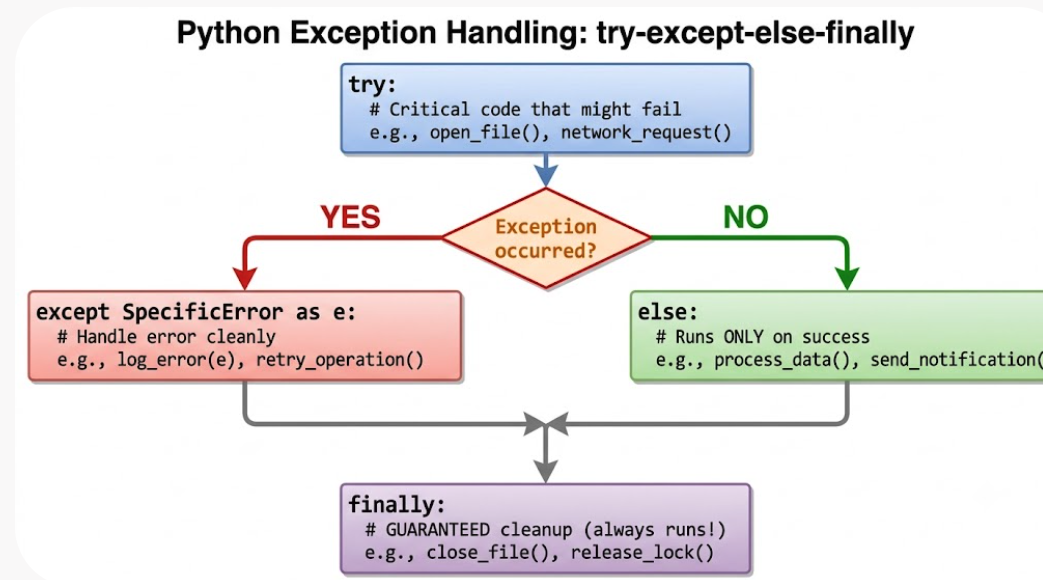

In [ ]:
# Teaching Exception Handling: Handling Division by Zero

def safe_divide(numerator, denominator):
    try:
        # Attempt division which might fail if denominator is 0
        result = numerator / denominator
        print(f"Success! {numerator} divided by {denominator} is {result}")
    except ZeroDivisionError:
        # This block runs only when a ZeroDivisionError is raised
        print("Error: You cannot divide a number by zero!")

# 1. Test with a valid division
print("--- Test 1 (Valid Division) ---")
safe_divide(10, 2)

# 2. Test with division by zero
print("\n--- Test 2 (Division by Zero) ---")
safe_divide(10, 0)

--- Test 1 (Valid Division) ---
Success! 10 divided by 2 is 5.0

--- Test 2 (Division by Zero) ---
Error: You cannot divide a number by zero!


In [ ]:
# 3.1 Basic Exception Handling: Intercepting Runtime Crashes
def divide_numbers(numerator, denominator):
    """Safely divides two numbers with exception handling."""
    try:
        result = numerator / denominator
    # Multiple exceptions can be caught by using multiple sequential except blocks:
    except ZeroDivisionError as err:
        # Using the 'as' keyword captures the exception instance into a variable (err)
        # so we can retrieve and print the error message payload directly.
        print(f"  [Handled Error] Cannot divide by zero! ({err})")
        return None
    except TypeError as err:
        # Here we capture another distinct exception type into a variable
        print(f"  [Handled Error] Invalid operand type! ({err})")
        return None
    else:
        print(f"  [Success] Division succeeded without errors.")
        return result
    finally:
        # The finally block ALWAYS runs, regardless of whether an exception was raised,
        # caught, or if a value was already returned. Perfect for closing files or database connections!
        print("  [Finally] Operation cycle completed.")

print("--- Test 1: Valid Division (10 / 4) ---")
print("Outcome:", divide_numbers(10, 4))

print("\n--- Test 2: Division by Zero (10 / 0) ---")
print("Outcome:", divide_numbers(10, 0))

print("\n--- Test 3: Type Mismatch (10 / 'five') ---")
print("Outcome:", divide_numbers(10, "five"))

--- Test 1: Valid Division (10 / 4) ---
  [Success] Division succeeded without errors.
  [Finally] Operation cycle completed.
Outcome: 2.5

--- Test 2: Division by Zero (10 / 0) ---
  [Handled Error] Cannot divide by zero! (division by zero)
  [Finally] Operation cycle completed.
Outcome: None

--- Test 3: Type Mismatch (10 / 'five') ---
  [Handled Error] Invalid operand type! (unsupported operand type(s) for /: 'int' and 'str')
  [Finally] Operation cycle completed.
Outcome: None


```markdown
### Guide to Common Python Exceptions

When writing robust applications, it is essential to understand the types of runtime errors Python can raise. Here are the most frequently encountered built-in exceptions:

* **`ValueError`**: Raised when a function receives an argument of the correct data type but an inappropriate value (e.g., trying to parse the string `"ABC"` into an integer).
* **`TypeError`**: Occurs when an operation or function is applied to an object of an inappropriate type (e.g., trying to add a string and an integer: `"5" + 2`).
* **`IndexError`**: Triggered when attempting to access an index that is out of range for a sequence like a list or a tuple (e.g., accessing `lst[10]` on a list of only 3 items).
* **`KeyError`**: Raised when looking up a key in a dictionary that does not exist.
* **`FileNotFoundError`**: Occurs when attempting to open or interact with a file path that does not exist on disk in read mode.
* **`ZeroDivisionError`**: Raised when the denominator of a division or modulo operation is zero.
* **`AttributeError`**: Triggered when trying to access an attribute or method on an object that does not possess it (e.g., calling `.append()` on a string).
```

In [ ]:
# 3.2 Common Standard Exception Types in Python
# 1. ValueError: Argument has right type but inappropriate value
try:
    int("3.1415")  # Cannot parse float string directly as int!
except ValueError as e:
    print("Caught ValueError:", e)

# 2. IndexError: Sequence subscript out of range
try:
    lst = [10, 20]
    print(lst[5])
except IndexError as e:
    print("Caught IndexError:", e)

# 3. KeyError: Dictionary key not found
try:
    d = {"name": "Sunil"}
    print(d["roll_no"])
except KeyError as e:
    print("Caught KeyError:", e)

# 4. FileNotFoundError: Attempting to open missing file in 'r' mode
try:
    open("ghost_file_12345.txt", "r")
except FileNotFoundError as e:
    print("Caught FileNotFoundError:", e)


Caught ValueError: invalid literal for int() with base 10: '3.1415'
Caught IndexError: list index out of range
Caught KeyError: 'roll_no'
Caught FileNotFoundError: [Errno 2] No such file or directory: 'ghost_file_12345.txt'


In [ ]:
# 3.3 Raising Exceptions & Custom Validation Rules
# The 'raise' keyword allows YOU to trigger exceptions when business invariants are violated!

def calculate_sensor_resistance(voltage_v, current_a):
    """
    Calculates electrical resistance: R = V / I
    Enforces positive current rule.
    """
    if not isinstance(voltage_v, (int, float)) or not isinstance(current_a, (int, float)):
        raise TypeError("Both voltage and current must be numeric integers or floats!")

    if current_a == 0:
        raise ZeroDivisionError("Current cannot be 0.0 Amperes (Open circuit condition)!")

    if current_a < 0:
        raise ValueError(f"Reverse current detected ({current_a} A); circuit expects forward bias!")

    resistance = voltage_v / current_a
    return resistance

# Testing valid computation:
print("Resistance (V=5V, I=0.02A):", calculate_sensor_resistance(5.0, 0.02), "Ohms")

# Testing triggered ValueError:
try:
    calculate_sensor_resistance(5.0, -0.05)
except ValueError as err:
    print("Successfully intercepted custom validation failure:", err)


Resistance (V=5V, I=0.02A): 250.0 Ohms
Successfully intercepted custom validation failure: Reverse current detected (-0.05 A); circuit expects forward bias!


In [ ]:
# 3.4 Defining Custom Exception Classes (Object-Oriented Error Handling)
# In professional systems, inherit from Python's base 'Exception' class:
# We will see this later. TAs please  note

class InsufficientStockError(Exception):
    """Raised when warehouse stock is inadequate for requested checkout."""
    def __init__(self, item_name, available, requested):
        self.item_name = item_name
        self.available = available
        self.requested = requested
        super().__init__(f"Cannot dispense {requested} units of '{item_name}'; only {available} in stock!")

def dispatch_hardware(item, stock, order_qty):
    if order_qty > stock:
        raise InsufficientStockError(item, stock, order_qty)
    print(f"[Dispatched] {order_qty} units of '{item}' sent to maker lab.")
    return stock - order_qty

# Test custom exception:
try:
    dispatch_hardware("ESP32-CAM", stock=5, order_qty=12)
except InsufficientStockError as err:
    print("Custom Exception Caught:")
    print(" ", err)
    print(f"  Shortfall = {err.requested - err.available} units needed from supplier.")


Custom Exception Caught:
  Cannot dispense 12 units of 'ESP32-CAM'; only 5 in stock!
  Shortfall = 7 units needed from supplier.


### In-Class Quick Check 3: Exception Handling
**Task**:
Write a function `parse_integer_input(user_str)` that converts `user_str` to an integer. If the string is not a valid integer, catch `ValueError` and return `-1`.


In [ ]:
# STUDENT ACTIVITY: Quick Check 3
# -------------------------------------------------------------
def parse_integer_input(user_str):
    # TODO: Implement try-except ValueError


print("parse_integer_input('450') =", parse_integer_input("450"))
print("parse_integer_input('ABC') =", parse_integer_input("ABC"))
assert parse_integer_input("450") == 450
assert parse_integer_input("ABC") == -1


---
# Part 4: File Handling Fundamentals & Context Managers
### Lecture Duration: ~15 mins

Computer RAM is volatile — data disappears when the script terminates. **Files** allow storing datasets, configurations, model weights, and logs permanently on non-volatile storage.

```
+-----------------------------------------------------------------------------------+
| 1. open(filepath, mode) : Obtains a file stream from the Operating System.        |
| 2. read / write         : Transfers data between memory and disk storage.         |
| 3. close()              : Flushes buffers and frees OS system file descriptor.   |
+-----------------------------------------------------------------------------------+
```

### Access Modes Taxonomy:
- `'r'`: Read (default). File must exist.
- `'w'`: Write. **Overwrites existing file** or creates new file.
- `'a'`: Append. Writes to the end of the file without overwriting existing data.
- `'r+'`: Read and Write update mode.
- `'rb'`, `'wb'`: Binary read and write (images, audio, byte arrays).

### The Context Manager (`with open(...) as f:`):
The `with` statement encapsulates file operations inside a context manager that **guarantees closure** when execution leaves the block, even if an unhandled exception or crash occurs!

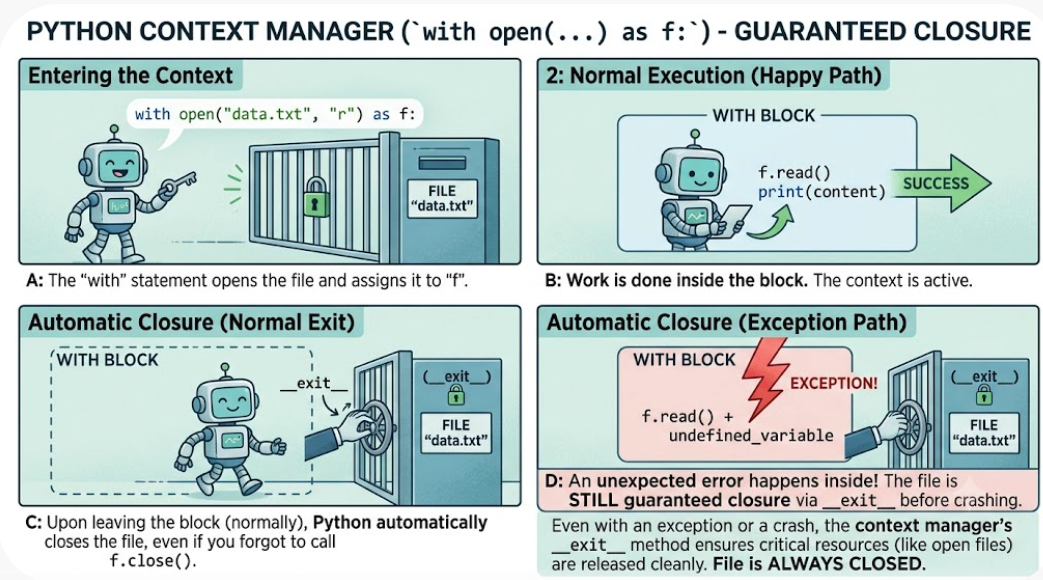



In [4]:
# 4.1 Writing Text to a File using 'with open(...) as f'
# Note: f.write() DOES NOT automatically append a newline; you must write '\n' explicitly!

sample_filename = "lecture_notes.txt"

with open(sample_filename, "w" ) as f:
    f.write("Line 1: Python File Handling Fundamentals\n")
    f.write("Line 2: Context managers guarantee safe resource cleanup\n")
    f.write("Line 3: Multiple lines can be written sequentially\n")

print(f"File '{sample_filename}' created and written successfully.")


File 'lecture_notes.txt' created and written successfully.


In [ ]:
# 4.2 Four Strategies for Reading Text Files
# Strategy 1: .read() — Reads the ENTIRE file into one single string
with open(sample_filename, "r" ) as f:
    complete_text = f.read()
print("=== Strategy 1: f.read() ===")
print(repr(complete_text))

# Strategy 2: .readline() — Reads ONE line at a time
with open(sample_filename, "r" ) as f:
    first_line = f.readline()
    second_line = f.readline()
print("\n=== Strategy 2: f.readline() ===")
print("First line :", first_line.strip())
print("Second line:", second_line.strip())

# Strategy 3: .readlines() — Reads all lines into a LIST of strings
with open(sample_filename, "r" ) as f:
    lines_list = f.readlines()
print("\n=== Strategy 3: f.readlines() ===")
print("List of lines:", lines_list)

# Strategy 4 (BEST PRACTICE FOR BIG DATA): Iterating directly over the file object!
# This streams lines lazily into memory one-at-a-time (O(1) memory footprint!)
print("\n=== Strategy 4: for line in file (Streaming) ===")
with open(sample_filename, "r", encoding="utf-8") as f:
    for line_num, line in enumerate(f, start=1):
        print(f"  [{line_num}] {line.strip()}")


=== Strategy 1: f.read() ===
'Line 1: Python File Handling Fundamentals\nLine 2: Context managers guarantee safe resource cleanup\nLine 3: Multiple lines can be written sequentially\n'

=== Strategy 2: f.readline() ===
First line : Line 1: Python File Handling Fundamentals
Second line: Line 2: Context managers guarantee safe resource cleanup

=== Strategy 3: f.readlines() ===
List of lines: ['Line 1: Python File Handling Fundamentals\n', 'Line 2: Context managers guarantee safe resource cleanup\n', 'Line 3: Multiple lines can be written sequentially\n']

=== Strategy 4: for line in file (Streaming) ===
  [1] Line 1: Python File Handling Fundamentals
  [2] Line 2: Context managers guarantee safe resource cleanup
  [3] Line 3: Multiple lines can be written sequentially


In [ ]:
# 4.3 Appending Data to an Existing File ('a' Mode)
# 'w' mode would destroy our previous lines. 'a' mode preserves them!

with open(sample_filename, "a" ) as f:
    f.write("Line 4: This line was appended later without deleting previous data\n")
    f.write("Line 5: Final concluding telemetry record\n")

# Verify that all 5 lines are present:
with open(sample_filename, "r", encoding="utf-8") as f:
    total_lines = len(f.readlines())
print(f"Total lines now in '{sample_filename}': {total_lines}")


Total lines now in 'lecture_notes.txt': 5


In [ ]:
# 4.4 Serializing Numbers into Text Files
# Reminder: f.write() strictly expects a string (str), NOT numbers!
# To save numbers, cast with str() or use f-strings:

scores_dataset = [98.5, 91.0, 84.5, 76.0, 89.5]

with open("scores_data.txt", "w", ) as f:
    for score in scores_dataset:
        f.write(f"{score:.2f}\n")  # Write formatted string with newline!

# Reading numbers back and restoring numeric types:
loaded_scores = []
with open("scores_data.txt", "r" ) as f:
    for line in f:
        loaded_scores.append(float(line.strip()))

print("Scores read back and converted to floats:", loaded_scores)
print("Computed Mean Score:", sum(loaded_scores) / len(loaded_scores))


Scores read back and converted to floats: [98.5, 91.0, 84.5, 76.0, 89.5]
Computed Mean Score: 87.9


In [ ]:
# 4.5 Demonstrating 'r+' (Read and Write) Mode
# The 'r+' mode opens an existing file for both reading and writing.
# Crucial Rules for 'r+':
# 1. The file MUST already exist; otherwise, Python raises a FileNotFoundError.
# 2. When writing, it overwrites characters from the CURRENT pointer position.
#    It does not truncate (empty) the file first, unlike 'w' mode.
# 3. Reading and writing share a single file pointer, so you must carefully
#    reposition the pointer using seek() when switching operations.

filename = "r_plus_demo.txt"

# Step 1: Pre-create the file to satisfy the existence constraint
with open(filename, "w") as f:
    f.write("Hello Python World")

# Step 2: Open in 'r+' mode to read and modify in-place
with open(filename, "r+") as f:
    # Read the current content
    original_content = f.read()
    print("Original File Content:", repr(original_content))

    # Move the file pointer back to index 6 to change 'Python' to 'Active'
    f.seek(6)
    f.write("Active")

    # Rewind pointer to the beginning to read the updated file
    f.seek(0)
    updated_content = f.read()
    print("Updated File Content :", repr(updated_content))

Original File Content: 'Hello Python World'
Updated File Content : 'Hello Active World'


### In-Class Quick Check 4: File I/O
**Task**:
1. Write a list of 4 fruits to `fruits.txt` (one per line).
2. Read the file back, strip the newlines, and store them into a list `fruits_loaded`.


In [ ]:
# STUDENT ACTIVITY: Quick Check 4
# -------------------------------------------------------------
my_fruits = ["Mango", "Jackfruit", "Banana", "Papaya"]

# TODO 1: Write to fruits.txt


# TODO 2: Read back into fruits_loaded
fruits_loaded = []


print("Loaded fruits:", fruits_loaded)
assert fruits_loaded == my_fruits


---
# Part 5: Advanced File Operations — Pointers & Directory Management

### 1. File Pointer Tracking: `tell()` and `seek()`
As you read from or write to a file, Python maintains an invisible cursor known as the **file pointer** (or stream position) to track where the next operation will take place.

*   **`f.tell()`**: Returns an integer representing the current **byte offset** of the file pointer from the beginning of the file.
*   **`f.seek(offset, whence=0)`**: Moves the file pointer to a new location.
    *   `offset`: The number of bytes to move the pointer.
    *   `whence`: Defines the reference point from which the offset is calculated:

| Value of `whence` | Constant Name | Reference Point | Description |
| :--- | :--- | :--- | :--- |
| **`0`** (Default) | `os.SEEK_SET` | **Beginning** of file | Moves the pointer relative to the start of the file. Offset must be $\ge 0$. |
| **`1`** | `os.SEEK_CUR` | **Current** position | Moves the pointer relative to where it is right now. (Mainly used in binary mode) |
| **`2`** | `os.SEEK_END` | **End** of file | Moves the pointer relative to the very end of the file. (Often used with negative offsets to read backwards) |

#### Visualizing Seek Navigation:
```
  H  e  l  l  o     W  o  r  l  d
  |  |                       |  |
 [0] [1]                    [10][11]
  ^                              ^
  |                              |
seek(0, 0)                  seek(0, 2)  <-- End of file pointer (Offset 11)
```

### 2. Operating System & Path Utilities (`os` and `os.path`)
When writing production-ready code, you should never assume a file path is valid or accessible. Python's built-in `os` module provides essential tools to query your local directory environment and check file properties before attempting I/O operations:

*   **`os.path.exists(path)`**: Returns `True` if the path exists on disk (can be a folder or a file), preventing `FileNotFoundError`.
*   **`os.path.isfile(path)`**: Returns `True` if the specified path points to a file rather than a directory.
*   **`os.path.getsize(path)`**: Returns the precise size of the target file in **bytes**.
*   **`os.listdir(dir)`**: Returns a list containing the names of the entries (files and directories) inside the given directory path.

In [ ]:
# Detailed Example: File Pointer Tracking & Operating System Utilities
import os

filename = "advanced_demo.txt"

# --- 1. Writing Sample Data ---
# Let's write three lines of exact 10-character padded blocks
with open(filename, "w", encoding="utf-8") as f:
    f.write("REC01:100\n")  # Offset  0 to  9 (10 bytes)
    f.write("REC02:200\n")  # Offset 10 to 19 (10 bytes)
    f.write("REC03:300\n")  # Offset 20 to 29 (10 bytes)

print("=== File Pointer Navigation Demo ===")
# --- 2. Pointer Operations ---
with open(filename, "r+") as f:
    print(f"Initial pointer location  : {f.tell()} (expecting 0)")

    # Read the first record block (10 characters)
    first_block = f.read(10)
    print(f"Read first record block   : {repr(first_block)}")
    print(f"Current pointer position  : {f.tell()}")

    # Jump straight to the numeric score of REC02 (offset 16)
    # Format is: REC02:200\n -> REC02 is 5 bytes, colon is 1 byte (total 6 bytes relative to line start)
    # Since REC02 starts at line 2 (offset 10), the target score begins at byte 16.
    f.seek(16)
    print(f"Moved pointer to          : {f.tell()}")

    # Overwrite "200" with "999" in-place
    f.write("999")
    print(f"Overwrote value. Position : {f.tell()}")

    # Rewind to start to verify complete file changes
    f.seek(0)
    updated_content = f.read()
    print(f"\nUpdated File Content:\n{updated_content}")

# --- 3. Directory and OS Path Inspection ---
print("\n=== OS Path Integrity Utilities ===")
if os.path.exists(filename):
    print(f"File '{filename}' exists on disk : True")
    print(f"Is it a regular file?             : {os.path.isfile(filename)}")
    print(f"File size on local storage        : {os.path.getsize(filename)} bytes")
else:
    print(f"File '{filename}' not found.")

=== File Pointer Navigation Demo ===
Initial pointer location  : 0 (expecting 0)
Read first record block   : 'REC01:100\n'
Current pointer position  : 10
Moved pointer to          : 16
Overwrote value. Position : 19

Updated File Content:
REC01:100
REC02:999
REC03:300


=== OS Path Integrity Utilities ===
File 'advanced_demo.txt' exists on disk : True
Is it a regular file?             : True
File size on local storage        : 30 bytes


In [ ]:
# Detailed Example: Harnessing 'os' and 'os.path' for Workspace Auditing
import os

# Let's inspect a couple of filenames we have worked with
target_files = ["lecture_notes.txt", "records.txt", "ghost_file.txt"]

print("=== Checking Individual File Metadata ===")
for filename in target_files:
    # 1. Check if the path exists on storage
    exists = os.path.exists(filename)

    if exists:
        # 2. Check if the path is a file (not a folder)
        is_file = os.path.isfile(filename)
        # 3. Retrieve file size in bytes
        file_size = os.path.getsize(filename)

        print(f"File: '{filename:<18}' | Exists: {exists!s:<5} | Is File: {is_file!s:<5} | Size: {file_size} bytes")
    else:
        print(f"File: '{filename:<18}' | Exists: {exists!s:<5} (Cannot query size)")

# 4. Listing directory contents to search for specific file types
print("\n=== Scanning Directory Contents (.txt files) ===")
current_directory = "."
try:
    # Read all entry names in the current folder directory
    all_entries = os.listdir(current_directory)

    # Filter only for .txt files
    text_files = [entry for entry in all_entries if entry.endswith(".txt")]

    print(f"Found {len(text_files)} text files in directory '{current_directory}':")
    for idx, txt_file in enumerate(text_files, 1):
        size = os.path.getsize(txt_file)
        print(f"  {idx}. {txt_file:<20} ({size} bytes)")
except Exception as e:
    print("Error reading directory contents:", e)

=== Checking Individual File Metadata ===
File: 'lecture_notes.txt ' | Exists: False (Cannot query size)
File: 'records.txt       ' | Exists: False (Cannot query size)
File: 'ghost_file.txt    ' | Exists: False (Cannot query size)

=== Scanning Directory Contents (.txt files) ===
Found 2 text files in directory '.':
  1. r_plus_demo.txt      (18 bytes)
  2. advanced_demo.txt    (30 bytes)


In [ ]:
# 5.1 Navigating the File Pointer with tell() and seek()
sample_phrase = "ABCDEFGH"

with open("pointer_demo.txt", "w+", encoding="utf-8") as f:
    f.write(sample_phrase)

    print(f"After writing '{sample_phrase}', pointer position (tell) = {f.tell()} bytes")

    # Rewind pointer back to the start (byte 0):
    f.seek(0)
    print(f"After f.seek(0), pointer position = {f.tell()} bytes")
    print("Reading first 3 characters:", f.read(3))  # 'ABC'
    print("Pointer is now at byte      :", f.tell())    # 3

    # Jump directly to byte offset 5:
    f.seek(5)
    print("After f.seek(5), reading remainder:", f.read())  # 'FGH'


After writing 'ABCDEFGH', pointer position (tell) = 8 bytes
After f.seek(0), pointer position = 0 bytes
Reading first 3 characters: ABC
Pointer is now at byte      : 3
After f.seek(5), reading remainder: FGH


In [ ]:
# 5.2 Operating System Path Management (os and os.path)
import os

target_file = "lecture_notes.txt"

# 1. Existence and type verification:
print(f"Does '{target_file}' exist? :", os.path.exists(target_file))
print(f"Is it a regular file?        :", os.path.isfile(target_file))

# 2. File size in bytes:
file_size_bytes = os.path.getsize(target_file)
print(f"File size on disk            : {file_size_bytes} bytes")

# 3. Listing current directory contents:
current_files = [f for f in os.listdir(".") if f.endswith(".txt")]
print("\nText files in workspace:")
for fname in current_files[:5]:
    print(f"  * {fname} ({os.path.getsize(fname)} bytes)")


Does 'lecture_notes.txt' exist? : True
Is it a regular file?        : True
File size on disk            : 260 bytes

Text files in workspace:
  * pointer_demo.txt (8 bytes)
  * scores_data.txt (30 bytes)
  * lecture_notes.txt (260 bytes)


---
# Part 6: Laboratory Practical Workbook  


Welcome to the Week 6 Laboratory Session!
- **Tier 1: Core Practical Problems (Mandatory C1 to C6 — 12 Marks)**: File ingestion with exception guards, formatted weather logs, CSV parser with `ValueError` recovery, word frequency counter, file pointer updates (`seek/tell`), and custom exception validators.
- **Tier 2: Advanced Extension Problems (Optional / Bonus A1 to A3 — 8 Marks)**: Inverted index search engine, server access log auditor,


---
## Tier 1: Core Laboratory Problems (Mandatory)

### Task C1: Safe File Ingestion with `FileNotFoundError` & `PermissionError` Guard
**Context**: Automated data ingestion pipelines must not crash when input files are missing or permissions are restricted.

**Problem Statement**:
1. Implement a function `safe_read_file(filepath, fallback_text="DEFAULT DATA")`:
   - Attempts to open and read `filepath` using `with open(filepath, 'r') as f:`.
   - If the file exists, returns its complete text content.
   - If `FileNotFoundError` occurs, logs a warning message and returns `fallback_text`.
   - If `PermissionError` occurs, logs an access-denied message and returns `fallback_text`.
2. Test the function on:
   - A missing file: `"missing_telemetry_2026.txt"`.
   - A valid created file: Create `"test_sample.txt"` containing `"ICFOSS Kerala 2026"`, read it, and verify the return value.


In [ ]:
# TASK C1: WORKSPACE
# -------------------------------------------------------------------

def safe_read_file(filepath, fallback_text="DEFAULT DATA"):
    """Safely reads a text file with FileNotFoundError and PermissionError handling."""
    # TODO: Implement the try-except-else-finally block below
    try:
        # 1. Attempt to open and read the file
        pass
    except FileNotFoundError as err:
        # 2. Handle missing file exception, print warning, and return fallback
        pass
    except PermissionError as err:
        # 3. Handle restricted permissions exception, print warning, and return fallback
        pass

# Test Case 1: Missing file
res_missing = safe_read_file("missing_telemetry_2026.txt", fallback_text="BACKUP_OK")
print("Missing File Result:", res_missing)

# Test Case 2: Create valid file and read it
with open("test_sample.txt", "w" ) as f:
    f.write("ICFOSS Kerala 2026")

res_valid = safe_read_file("test_sample.txt")
print("Valid File Result  :", res_valid)

  [Warning] File 'missing_telemetry_2026.txt' not found. Using fallback text.
Missing File Result: BACKUP_OK
Valid File Result  : ICFOSS Kerala 2026


### Task C2: Environmental Weather Log Exporter (Writing & Appending Modes)
**Context**: Atmospheric recording stations write periodic weather telemetry to structured text files.

**Problem Statement**:
1. Implement a function `create_weather_log(filepath, initial_readings)`:
   - Opens `filepath` in write mode (`'w'`).
   - Writes a standard header line: `Timestamp,Temperature_C,Humidity_Pct,Pressure_hPa
`.
   - Writes each reading tuple `(timestamp, temp, humidity, pressure)` formatted as comma-separated values.
2. Implement a function `append_weather_reading(filepath, new_reading)`:
   - Opens `filepath` in append mode (`'a'`).
   - Appends `new_reading` as a new line without overwriting previous data.
3. Test by creating `weather_log.txt` with 3 initial records, then appending a 4th record. Read back all lines and print the complete log.


In [ ]:
# TASK C2: WORKSPACE
# -------------------------------------------------------------------

def create_weather_log(filepath, initial_readings):
    """Creates a new weather log file with headers and initial readings."""
    # TODO: Open the file in write ('w') mode and write the CSV header:
    # "Timestamp,Temperature_C,Humidity_Pct,Pressure_hPa\n"
    # Then loop through initial_readings and write each row.
    pass


def append_weather_reading(filepath, new_reading):
    """Appends a single observation row to the existing log file."""
    # TODO: Open the file in append ('a') mode and append the new reading row.
    pass


# Sample validation data:
initial_data = [
    ("2026-09-29 06:00", 24.2, 85.0, 1012.3),
    ("2026-09-29 12:00", 32.5, 62.0, 1010.8),
    ("2026-09-29 18:00", 28.0, 74.0, 1011.5)
]

evening_record = ("2026-09-29 21:00", 25.8, 80.0, 1012.0)

# Execute functions:
log_file = "weather_log.txt"
create_weather_log(log_file, initial_data)
append_weather_reading(log_file, evening_record)

# Read and display final file:
try:
    with open(log_file, 'r', encoding='utf-8') as f:
        print(f.read())
except FileNotFoundError:
    print("[Error] weather_log.txt was not found. Please implement the functions above.")

Timestamp,Temperature_C,Humidity_Pct,Pressure_hPa
2026-09-29 06:00,24.2,85.0,1012.3
2026-09-29 12:00,32.5,62.0,1010.8
2026-09-29 18:00,28.0,74.0,1011.5
2026-09-29 21:00,25.8,80.0,1012.0



In [ ]:
# C2 VERIFICATION TEST CELL (Do not modify)
with open("weather_log.txt", "r", encoding="utf-8") as f:
    lines = f.readlines()

assert len(lines) == 5, f"Expected 5 lines (header + 4 rows), got {len(lines)}"
assert lines[0].strip() == "Timestamp,Temperature_C,Humidity_Pct,Pressure_hPa"
assert lines[-1].startswith("2026-09-29 21:00"), "Appended row mismatch"
print(" Task C2 Logic Verified Successfully!")


### Task C3: Sensor CSV Parser with `ValueError` Exception Guard
**Context**: Real-world scientific CSV datasets frequently contain corrupted tokens, missing fields, or sensor dropout strings (`"ERR"`, `"NULL"`, `"TIMEOUT"`).

**Problem Statement**:
1. First, create a simulated raw data file `sensor_stream.csv` containing mixed valid and invalid rows:
   ```
   Sensor_ID,Voltage,Status
   S101,4.92,NORMAL
   S102,ERR_DISCONNECT,FAULT
   S103,4.88,NORMAL
   S104,NULL,TIMEOUT
   S105,5.01,NORMAL
   S106,-99.0,OUT_OF_BOUNDS
   ```
2. Implement `parse_sensor_data(filepath)`:
   - Reads the file line by line.
   - Skips the header line.
   - Uses `.strip()` and `.split(',')` to extract fields.
   - Wraps the voltage conversion in a `try-except ValueError` block.
   - Filters out voltages that fail numerical conversion or are negative.
   - Computes the average voltage of all valid sensors.
   - Returns a tuple `(valid_sensor_count, average_voltage, list_of_faulty_ids)`.


In [ ]:
# TASK C3: WORKSPACE
# -------------------------------------------------------------------

sample_csv_content = """Sensor_ID,Voltage,Status
S101,4.92,NORMAL
S102,ERR_DISCONNECT,FAULT
S103,4.88,NORMAL
S104,NULL,TIMEOUT
S105,5.01,NORMAL
S106,-99.0,OUT_OF_BOUNDS
"""

with open("sensor_stream.csv", "w", encoding="utf-8") as f:
    f.write(sample_csv_content)

def parse_sensor_data(filepath):
    """Parses sensor voltages while gracefully catching ValueErrors."""
    valid_voltages = []
    faulty_sensor_ids = []

    with open(filepath, "r", encoding="utf-8") as f:
        # TODO 1: Skip the header line

        # TODO 2: Loop over each line
        for line in f:
            # Strip whitespace and split by comma
            # Attempt to convert voltage to float inside a try-except block
            # If successful and positive, append to valid_voltages
            # If conversion fails (ValueError) or voltage is negative, add Sensor_ID to faulty_sensor_ids
            pass

    valid_count = len(valid_voltages)
    avg_v = sum(valid_voltages) / valid_count if valid_count > 0 else 0.0
    return valid_count, round(avg_v, 3), faulty_sensor_ids

count, avg_volt, faults = parse_sensor_data("sensor_stream.csv")
print(f"Valid Sensors Count : {count}")
print(f"Average Voltage     : {avg_volt} V")
print(f"Faulty Sensor IDs   : {faults}")

Valid Sensors Count : 3
Average Voltage     : 4.937 V
Faulty Sensor IDs   : ['S102', 'S104', 'S106']


### Task C4: Text File Word Frequency & Summary Exporter
**Context**: Natural language processing pipelines ingest raw text corpora, compute term frequencies, and export summaries.

**Problem Statement**:
1. Create a sample research abstract file `ai_abstract.txt`:
   ```
   Artificial intelligence and machine learning are transforming research.
   Machine learning enables automated data analysis, while artificial intelligence
   drives modern robotics. Open source software accelerates this artificial intelligence revolution.
   ```
2. Implement `generate_word_frequency(input_file, output_file)`:
   - Reads `input_file` safely.
   - Cleans text: converts to lowercase, replaces punctuation (`.`, `,`, `
`) with spaces.
   - Tokenizes into individual words using `.split()`.
   - Computes word frequencies using a dictionary.
   - Sorts the dictionary in descending order of frequency.
   - Writes the formatted frequency report to `output_file` in the format: `word: count
`.


In [ ]:
# TASK C4: WORKSPACE
# -------------------------------------------------------------------

sample_abstract = """Artificial intelligence and machine learning are transforming research.
Machine learning enables automated data analysis, while artificial intelligence
drives modern robotics. Open source software accelerates this artificial intelligence revolution.
"""

with open("ai_abstract.txt", "w", encoding="utf-8") as f:
    f.write(sample_abstract)

def generate_word_frequency(input_file, output_file):
    """Generates word frequency histogram and exports report to file."""
    freq_dict = {}

    # TODO 1: Read the file safely and load its content

    # TODO 2: Clean the text: convert to lowercase and remove punctuation (. and ,)

    # TODO 3: Split into individual words and count frequencies using a dictionary

    # TODO 4: Sort frequencies in descending order and write the formatted report
    # (e.g. "word: count\n") to the specified output_file

    return freq_dict

# Test execution:
freqs = generate_word_frequency("ai_abstract.txt", "word_frequencies.txt")
print("Top 5 Words in Abstract:")
for w, c in sorted(freqs.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"  {w:<14}: {c}")

Top 5 Words in Abstract:
  artificial    : 3
  intelligence  : 3
  machine       : 2
  learning      : 2
  and           : 1


### Task C5: Random-Access File Manipulation (`seek()` and `tell()`)
**Context**: Binary protocols, database engines, and operating systems modify record blocks in-place without rewriting entire multi-gigabyte files.

**Problem Statement**:
1. Create a text file `records.txt` with fixed-width records:
   ```
   1001,Alice,85
   1002,Bob__,72
   1003,Carol,90
   ```
   *(Each line is exactly $14$ bytes: 4-digit ID + comma + 5-char name + comma + 2-digit mark + `
` = $4+1+5+1+2+1 = 14$ bytes).*
2. Open `records.txt` in read/write update mode (`'r+'`).
3. Use `tell()` to check your initial pointer position ($0$).
4. Use `seek(25, 0)` to jump directly to Bob's mark field and overwrite `'72'` with `'95'`.
5. Rewind with `seek(0)` and verify that Bob's score was updated while Alice and Carol remained intact.


In [ ]:
# TASK C5: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------

# Step 1: Create the initial fixed-width records file
with open("records.txt", "w", encoding="utf-8") as f:
    # TODO 1: Write the following three lines to the file
    # "1001,Alice,85\n"
    # "1002,Bob__,72\n"
    # "1003,Carol,90\n"
    pass

# Step 2: Open and modify Bob's score in-place using 'r+'
with open("records.txt", "r+", encoding="utf-8") as f:
    init_pos = f.tell()
    print("Initial File Pointer Position:", init_pos)

    # TODO 2: Jump directly to Bob's score position (offset 25 bytes from start)
    # and write "95" to overwrite "72"

    print("Moved Pointer to:", f.tell())

    # TODO 3: Rewind the pointer back to the beginning (offset 0) to read the full file

    updated_content = f.read()

print("\nUpdated File Content:")
print(updated_content)

Initial File Pointer Position: 0
Moved Pointer to: 25

Updated File Content:
1001,Alice,85
1002,Bob__,95
1003,Carol,90



### Task C6: Custom Exception Raising (`raise ValueError` / `TypeError`)
**Context**: Defensive programming validates user and sensor data ranges before saving to disk.

**Problem Statement**:
1. Implement a function `register_student(filename, name, roll_no, mark)`:
   - Validates that `name` is a non-empty string. If not, raises `TypeError("Name must be a non-empty string")`.
   - Validates that `roll_no` is a positive integer. If not, raises `ValueError("Roll number must be a positive integer")`.
   - Validates that `mark` is between $0.0$ and $100.0$. If not, raises `ValueError(f"Mark {mark} out of valid range [0, 100]")`.
   - If all validations pass, appends the record `f"{roll_no},{name},{mark:.1f}
"` to `filename`.
2. Demonstrate that the function correctly writes valid records and raises descriptive exceptions on invalid inputs.


In [ ]:
# TASK C6: WORKSPACE
# -------------------------------------------------------------------

def register_student(filename, name, roll_no, mark):
    """Validates student data ranges and appends record to file."""
    # TODO 1: Validate name (must be a non-empty string).
    # If invalid, raise TypeError("Name must be a non-empty string")
    pass

    # TODO 2: Validate roll_no (must be a positive integer).
    # If invalid, raise ValueError("Roll number must be a positive integer")
    pass

    # TODO 3: Validate mark range [0.0, 100.0].
    # If invalid, raise ValueError(f"Mark {mark} out of valid range [0, 100]")
    pass

    # TODO 4: If all validations pass, append the formatted record to the file:
    # f"{roll_no},{name.strip()},{mark:.1f}\n"
    pass

# Initialize clean file:
open("registry.txt", "w").close()

# 1. Valid insertion:
try:
    register_student("registry.txt", "Anjana J", 101, 94.5)
    register_student("registry.txt", "Renij R", 102, 92.0)
    print("Valid registrations completed.")
except Exception as e:
    print("Unexpected error during valid registration:", e)

# 2. Testing exception raising:
try:
    register_student("registry.txt", "Deepak", 103, 105.0)  # Invalid mark > 100!
except ValueError as e:
    print("Caught Expected Validation Error:", e)


Valid registrations completed.
Caught Expected Validation Error: Mark 105.0 out of valid range [0, 100]


---
## Section 4: Tier 2 — Advanced Extension Problems (Optional Bonus)
*Recommended for students with prior programming experience seeking bonus marks.*


### Task A1: Multi-Document Inverted Search Engine
**Context**: Information retrieval systems (Google, Lucene) index multiple text documents into an inverted index mapping each word to the set of document names containing it.

**Problem Statement**:
1. Create three sample documents:
   - `doc1.txt`: `"python data science machine learning"`
   - `doc2.txt`: `"artificial intelligence machine learning deep learning"`
   - `doc3.txt`: `"python open source software data science"`
2. Implement `build_inverted_index(doc_paths)`:
   - Opens and reads each document in `doc_paths` safely using `try-except`.
   - Splits text into unique words.
   - Builds an index dictionary: `{ word: {set of doc_names} }`.
3. Query the index: Find all documents that contain **both** `"python"` AND `"data"` using set intersection!


In [ ]:
# TASK A1: WORKSPACE (ADVANCED)
 # -------------------------------------------------------------

docs = {
    "doc1.txt": "python data science machine learning",
    "doc2.txt": "artificial intelligence machine learning deep learning",
    "doc3.txt": "python open source software data science"
}

# Create sample files on disk
for name, content in docs.items():
    with open(name, "w", encoding="utf-8") as f:
        f.write(content)

def build_inverted_index(doc_paths):
    """Constructs an inverted index mapping words to sets of filenames."""
    index = {}
    # TODO: Implement the inverted index logic:
    # 1. Loop through each document path in doc_paths
    # 2. Read the file contents safely
    # 3. Clean and split the contents into individual words
    # 4. Populate the 'index' dictionary mapping each unique word to a set of document names containing it
    pass
    return index

inv_index = build_inverted_index(list(docs.keys()))

# Query: Find documents containing both 'python' AND 'data':
python_docs = inv_index.get("python", set())
data_docs = inv_index.get("data", set())
matching_docs = python_docs & data_docs

print("Inverted Index Sample:")
for word in ["python", "learning", "data", "software"]:
    print(f"  {word:<10} -> {inv_index.get(word)}")

print(f"\nQuery: 'python' AND 'data' -> Found in: {matching_docs}")


Inverted Index Sample:
  python     -> {'doc3.txt', 'doc1.txt'}
  learning   -> {'doc2.txt', 'doc1.txt'}
  data       -> {'doc3.txt', 'doc1.txt'}
  software   -> {'doc3.txt'}

Query: 'python' AND 'data' -> Found in: {'doc3.txt', 'doc1.txt'}
 Task A1 Verified Successfully!


### Task A2: Production Server Log Exception Auditor
**Context**: DevOps and site reliability engineers automate log parsing to identify server failures.

**Problem Statement**:
1. Create a simulated server access log `server_access.log`:
   ```
   2026-09-29 10:14:01 192.168.1.10 GET /api/v1/sensors 200 45ms
   2026-09-29 10:14:05 192.168.1.25 POST /api/v1/telemetry 500 120ms
   2026-09-29 10:14:12 172.16.0.4 GET /favicon.ico 404 12ms
   2026-09-29 10:14:18 192.168.1.50 GET /dashboard 200 85ms
   2026-09-29 10:14:22 10.0.0.15 POST /login 503 340ms
   ```
2. Implement `audit_server_errors(log_file, error_report_file)`:
   - Parses each line.
   - Extracts lines where the HTTP status code is $\ge 400$ ($4xx$ client errors and $5xx$ server faults).
   - Writes an itemized incident report containing: `Timestamp | Client_IP | Endpoint | StatusCode` to `error_report_file`.
   - Returns the total count of error incidents detected.


In [ ]:
# TASK A2: WORKSPACE (ADVANCED)
 # -------------------------------------------------------------
simulated_log = """2026-09-29 10:14:01 192.168.1.10 GET /api/v1/sensors 200 45ms
2026-09-29 10:14:05 192.168.1.25 POST /api/v1/telemetry 500 120ms
2026-09-29 10:14:12 172.16.0.4 GET /favicon.ico 404 12ms
2026-09-29 10:14:18 192.168.1.50 GET /dashboard 200 85ms
2026-09-29 10:14:22 10.0.0.15 POST /login 503 340ms
"""

with open("server_access.log", "w", encoding="utf-8") as f:
    f.write(simulated_log)

def audit_server_errors(log_file, error_report_file):
    """Filters server errors (>= 400) and exports incident summary."""
    error_count = 0

    # TODO 1: Open 'log_file' for reading and 'error_report_file' for writing.
    # TODO 2: Write a cleanly formatted header to the report file, e.g.:
    # "TIMESTAMP           | CLIENT_IP    | ENDPOINT            | STATUS\n"
    # "-----------------------------------------------------------------\n"
    # TODO 3: Loop through each line in 'log_file':
    #   - Parse the date, time, client IP, method, endpoint, status code, and latency.
    #   - Convert the status code to an integer.
    #   - If status code >= 400, format the row and write to 'error_report_file', then increment error_count.
    pass

    return error_count

err_total = audit_server_errors("server_access.log", "error_audit_report.txt")
print(f"Total Server Incidents (>= 400): {err_total}\n")

try:
    with open("error_audit_report.txt", "r", encoding="utf-8") as f:
        print(f.read())
except FileNotFoundError:
    print("[Error] error_audit_report.txt was not found. Please implement the audit logic.")


Total Server Incidents (>= 400): 3
TIMESTAMP           | CLIENT_IP    | ENDPOINT            | STATUS
-----------------------------------------------------------------
2026-09-29 10:14:05 | 192.168.1.25 | /api/v1/telemetry   | 500
2026-09-29 10:14:12 | 172.16.0.4   | /favicon.ico        | 404
2026-09-29 10:14:22 | 10.0.0.15    | /login              | 503

 Task A2 Verified Successfully!


---
## Section 6: Laboratory Evaluation Rubric & Sign-Off Sheet

```
========================================================================================
CRITERION                                  MAX MARKS    AWARDED MARKS    REMARKS
========================================================================================
1. Pre-Lab & Code Reading (§1 & §2)            5          _______        _______________
2. Tier 1 Core Problems (§3: C1–C6 complete)  10          _______        _______________
3. Exception Robustness & Code Modularity      5          _______        _______________
4. Tier 2 Advanced Problems (§4)     5          _______        _______________
----------------------------------------------------------------------------------------
TOTAL SCORE                                   25          _______ / 25
========================================================================================

Teaching Assistant Signature : _________________________________
Faculty Instructor Signature : Dr. Sunil TT (Director, ICFOSS)
Date of Evaluation           : _________________________________
```
